In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [2]:
path_snow = "data/FORCING_snow.nc"
path_rain = "data/FORCING_rain.nc"
path_fsm=r'data/FSM_all_corr.nc'
ds_snow=xr.open_dataset(path_snow,decode_times=True)
ds_rain=xr.open_dataset(path_rain,decode_times=True)
ds_fsm_full=xr.open_dataset(path_fsm,decode_times=True)
ds_snow = ds_snow.assign_coords(xx=ds_fsm_full.xx.values,yy=ds_fsm_full.yy.values)
ds_rain = ds_rain.assign_coords(xx=ds_fsm_full.xx.values,yy=ds_fsm_full.yy.values)
ds_snow = ds_snow.coarsen(time=24, boundary="trim").sum()
ds_rain = ds_rain.coarsen(time=24, boundary="trim").sum()
ds_snow['Snowf_sum'] = ds_snow['Snowf']*3600
ds_rain['Rainf_sum'] = ds_rain['Rainf']*3600
ds_snow['Prec_sum'] = xr.ufuncs.add(ds_snow['Snowf_sum'],ds_rain['Rainf_sum'])

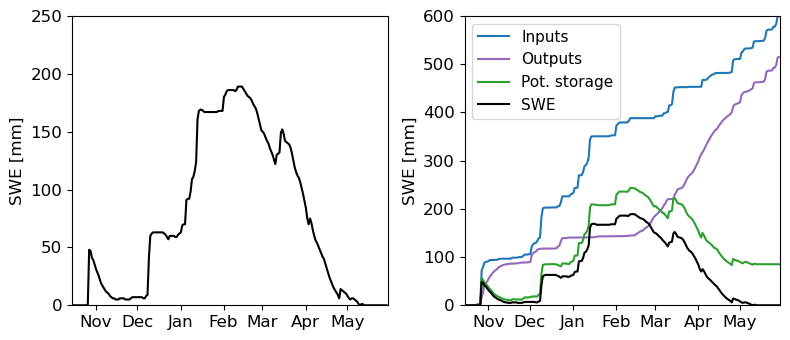

In [ ]:
i = 28
start_time = datetime(2018, 10, 15,6, 0)

end_time = datetime(2019, 5, 30, 5, 0)

ds_fsm = ds_fsm_full.isel(xx=i,yy=i).sel(time=slice(start_time,end_time))
input = ds_snow['Prec_sum'].isel(xx=i,yy=i).sel(time=slice(start_time,end_time))
input = input.assign_coords(time=ds_fsm.time).cumsum()

# --- Create subplots ---
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

ax = axs[0]
ax.plot(ds_fsm['time'].values, ds_fsm['swet_for'].values, c='black')
ax.set_ylim(0, 250)

ax = axs[1]
output_fsm = ds_fsm['sbsc_for'].cumsum() + ds_fsm['rotc_for'].cumsum()
storage_fsm = xr.ufuncs.subtract(input,output_fsm)
ax.plot(ds_fsm['time'].values, input, c='tab:blue',label = 'Inputs')
ax.plot(ds_fsm['time'].values, output_fsm, c = 'tab:purple',label = 'Outputs')
ax.plot(ds_fsm['time'].values, storage_fsm, c = 'tab:green',label = 'Pot. storage')
ax.plot(ds_fsm['time'].values, ds_fsm['swet_for'].values, c='black' ,label = 'SWE')
ax.set_ylim(0, 600)
ax.legend(fontsize = 11)


for i in np.arange(2) :
    axs[i].tick_params(labelsize=12)
    axs[i].xaxis.set_major_locator(mdates.MonthLocator())     # one tick per month
    axs[i].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axs[i].set_xlim(datetime(2018, 10, 15), datetime(2019, 5, 30))
    axs[i].set_ylabel('SWE [mm]',fontsize=12)
plt.tight_layout()
plt.show()